<a href="https://colab.research.google.com/github/jiaxian-wang/walmart-hurricane-project/blob/main/notebooks/walmart_hurricane_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Team: Water Duo**

**Members: Anya Chang and Jiaxian Wang**

## 1. Data Loading & Cleaning


In [1]:
from pathlib import Path
import subprocess
import pandas as pd
import sqlite3

# Clone the team repository if it is not already available
repo = Path("/content/walmart-hurricane-project")

if not repo.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/jiaxian-wang/walmart-hurricane-project.git",
        str(repo)
    ], check=True)

# Load datasets from the repository
data_dir = repo / "data"

transactions = pd.read_csv(data_dir / "walmart_transactions.csv")
stores = pd.read_csv(data_dir / "store_locations.csv")
products = pd.read_csv(data_dir / "product_catalog.csv")
distribution_centers = pd.read_csv(data_dir / "distribution_centers.csv")

# Load SQLite tables
conn = sqlite3.connect(data_dir / "inventory_and_sales.db")

daily_sales = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary", conn
)
inventory = pd.read_sql_query(
    "SELECT * FROM inventory_levels", conn
)

conn.close()

# Verify successful loading
for name, df in {
    "Transactions": transactions,
    "Stores": stores,
    "Products": products,
    "Distribution Centers": distribution_centers,
    "Daily Sales": daily_sales,
    "Inventory": inventory
}.items():
    print(f"{name}: {df.shape}")



Transactions: (25562, 8)
Stores: (14, 8)
Products: (45, 7)
Distribution Centers: (5, 8)
Daily Sales: (3600, 5)
Inventory: (4320, 6)


In [2]:
# Keep the original data unchanged
raw_count = len(transactions)
cleaned_sales = transactions.copy()

# 1. Remove exact duplicate records
cleaned_sales = cleaned_sales.drop_duplicates().copy()
duplicates_removed = raw_count - len(cleaned_sales)

# 2. Standardize store IDs
def normalize_store_id(series):
    return (series.astype("string").str.strip().str.upper()
            .str.replace(r"^FL[-_ ]?(\d{3})$", r"FL-\1", regex=True))

cleaned_sales["store_id"] = normalize_store_id(cleaned_sales["store_id"])

# 3. Clean product identifiers and categories
for col in ["sku", "product_name", "category"]:
    cleaned_sales[col] = cleaned_sales[col].astype("string").str.strip()

cleaned_sales["sku"] = cleaned_sales["sku"].str.upper()
cleaned_sales["category"] = cleaned_sales["category"].str.title()

# 4. Convert prices and quantities to numeric
cleaned_sales["unit_price"] = pd.to_numeric(
    cleaned_sales["unit_price"].astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

cleaned_sales["quantity"] = pd.to_numeric(
    cleaned_sales["quantity"], errors="coerce"
)

# 5. Parse mixed timestamp formats
cleaned_sales["timestamp_raw"] = cleaned_sales["timestamp"]

def parse_timestamps(series):
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    formats = [
        "%Y-%m-%dT%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%m/%d/%Y %H:%M",
        "%m-%d-%Y %H:%M:%S",
        "%d-%b-%Y %H:%M"
    ]
    for fmt in formats:
        missing = parsed.isna()
        parsed.loc[missing] = pd.to_datetime(
            series.loc[missing], format=fmt, errors="coerce"
        )
    return parsed

cleaned_sales["timestamp"] = parse_timestamps(cleaned_sales["timestamp"])

# 6. Flag problematic records
cleaned_sales["missing_timestamp"] = cleaned_sales["timestamp"].isna()
cleaned_sales["invalid_price"] = cleaned_sales["unit_price"].isna()
cleaned_sales["negative_quantity"] = cleaned_sales["quantity"] < 0

# 7. Clean store information
cleaned_stores = stores.copy()
cleaned_stores["store_id"] = normalize_store_id(cleaned_stores["store_id"])
cleaned_stores = cleaned_stores.drop_duplicates()

# 8. Validate store join
sales_with_stores = cleaned_sales.merge(
    cleaned_stores,
    on="store_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(sales_with_stores) == len(cleaned_sales)

print("Original rows:", raw_count)
print("Cleaned rows:", len(cleaned_sales))
print("Duplicates removed:", duplicates_removed)
print("Missing timestamps:", cleaned_sales["missing_timestamp"].sum())
print("Invalid prices:", cleaned_sales["invalid_price"].sum())
print("Negative quantities:", cleaned_sales["negative_quantity"].sum())
print("Unmatched stores:", (sales_with_stores["_merge"] == "left_only").sum())


# Check whether unparsed timestamps contain actual values
failed_dates = cleaned_sales.loc[
    cleaned_sales["timestamp"].isna(), "timestamp_raw"
]

print("Unparsed timestamps:", len(failed_dates))
print("Non-empty unparsed values:", failed_dates.notna().sum())
print(failed_dates.dropna().value_counts().head(10))

Original rows: 25562
Cleaned rows: 25532
Duplicates removed: 30
Missing timestamps: 884
Invalid prices: 0
Negative quantities: 130
Unmatched stores: 0
Unparsed timestamps: 884
Non-empty unparsed values: 0
Series([], Name: count, dtype: int64)


In [3]:
# Document the data cleaning decisions
decision_log = pd.DataFrame([
    {
        "Issue": "Duplicate records",
        "Decision": "Remove exact duplicates",
        "Rows affected": duplicates_removed
    },
    {
        "Issue": "Missing timestamps",
        "Decision": "Flag and exclude from date-based analysis",
        "Rows affected": int(cleaned_sales["missing_timestamp"].sum())
    },
    {
        "Issue": "Invalid prices",
        "Decision": "Convert to numeric and flag invalid values",
        "Rows affected": int(cleaned_sales["invalid_price"].sum())
    },
    {
        "Issue": "Negative quantities",
        "Decision": "Keep and flag pending verification",
        "Rows affected": int(cleaned_sales["negative_quantity"].sum())
    },
    {
        "Issue": "Inconsistent store IDs",
        "Decision": "Standardize store ID format",
        "Rows affected": int(
            (transactions["store_id"].astype("string") !=
             cleaned_sales.reindex(transactions.index)["store_id"]).fillna(False).sum()
        )
    }
])

display(decision_log)


,Issue,Decision,Rows affected
0,Duplicate records,Remove exact duplicates,30
1,Missing timestamps,Flag and exclude from date-based analysis,884
2,Invalid prices,Convert to numeric and flag invalid values,0
3,Negative quantities,Keep and flag pending verification,130
4,Inconsistent store IDs,Standardize store ID format,4345


In [4]:
# Consolidate known strawberry Pop-Tarts SKU variants
sku_mapping = {
    "PT-12": "Pop-Tarts Strawberry",
    "SKU#459812": "Pop-Tarts Strawberry",
    "POPTART-STRAW": "Pop-Tarts Strawberry",
    "PT_STRAWBERRY": "Pop-Tarts Strawberry"
}

# Preserve other SKUs until their equivalence is verified
cleaned_sales["canonical_product"] = (
    cleaned_sales["sku"].map(sku_mapping)
    .fillna(cleaned_sales["sku"])
)

before_skus = cleaned_sales["sku"].nunique()
after_products = cleaned_sales["canonical_product"].nunique()

# Verify that SKU grouping does not change sales quantity
total_before = cleaned_sales["quantity"].sum()
total_after = cleaned_sales.groupby("canonical_product")["quantity"].sum().sum()

assert total_before == total_after

mapping_table = pd.DataFrame(
    sku_mapping.items(),
    columns=["Original SKU", "Canonical Product"]
)

print("Original SKUs:", before_skus)
print("Canonical product groups:", after_products)
print("Total quantity unchanged:", total_before == total_after)

display(mapping_table)


Original SKUs: 45
Canonical product groups: 42
Total quantity unchanged: True


,Original SKU,Canonical Product
0,PT-12,Pop-Tarts Strawberry
1,SKU#459812,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,Pop-Tarts Strawberry


In [5]:
# Final data cleaning validation
catalog_skus = set(
    products["sku"].astype("string").str.strip().str.upper()
)

transaction_skus = set(cleaned_sales["sku"].dropna())

# Verify that cleaned transactions have valid identifiers
assert cleaned_sales["transaction_id"].is_unique
assert cleaned_sales["store_id"].notna().all()
assert transaction_skus.issubset(catalog_skus)

# Verify store ID coverage
assert cleaned_stores["store_id"].is_unique
assert set(cleaned_sales["store_id"]).issubset(
    set(cleaned_stores["store_id"])
)

# Verify duplicate removal and timestamp handling
assert len(cleaned_sales) == len(transactions) - duplicates_removed
assert cleaned_sales["timestamp"].notna().sum() == (
    len(cleaned_sales) - cleaned_sales["missing_timestamp"].sum()
)

print("All cleaning validation checks passed.")
print("Unique stores:", cleaned_stores["store_id"].nunique())
print("Valid transaction SKUs:", len(transaction_skus))
print("Unmatched SKUs:", len(transaction_skus - catalog_skus))


All cleaning validation checks passed.
Unique stores: 12
Valid transaction SKUs: 45
Unmatched SKUs: 0


### Data Cleaning Summary

We cleaned the transaction data by removing 30 duplicate records, standardizing store IDs and product identifiers, converting prices and quantities to numeric values, and parsing inconsistent timestamp formats. This helped us reduce the dataset from 25,562 to 25,532 rows.

We identified 884 missing timestamps and confirmed that all of them are missing in the original data rather than caused by parsing errors. These records are flagged for exclusion from time-based analysis. We also identified 130 negative quantities, which were retained and flagged for further investigation.

We combined four known strawberry Pop-Tarts SKU variants into one canonical product group and verified that total recorded quantity remain unchanged. Eventually, we joined the cleaned transactions with store information and confirmed that the join preserved the row count with no unmatched stores.

In Q2, we mapped all 45 SKUs to 20 product groups. Flagged records will be handled appropriately in subsequent analysis.

## 2. Weather API & Join


In [6]:
import time
import requests

# Fetch historical weather data from Open-Meteo
def fetch_weather():
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": 28.5383,
        "longitude": -81.3792,
        "start_date": "2024-09-01",
        "end_date": "2024-09-30",
        "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
        "timezone": "America/New_York",
        "temperature_unit": "celsius",
        "wind_speed_unit": "kmh",
        "precipitation_unit": "mm"
    }

    # Retry up to three times if the API request fails
    for attempt in range(3):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            data = response.json()
            break
        except requests.exceptions.RequestException as error:
            print(f"Attempt {attempt + 1} failed: {error}")
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)

    # Convert the API response into a DataFrame
    weather = pd.DataFrame(data["daily"])
    weather = weather.rename(columns={"time": "date"})
    weather["date"] = pd.to_datetime(weather["date"])

    # Add store information and data source
    weather["store_id"] = "FL-239"
    weather["timezone"] = params["timezone"]
    weather["source"] = "Open-Meteo Historical Weather API"

    print("Request URL:", response.url)
    print("Units:", data["daily_units"])

    return weather

weather_df = fetch_weather()

print("Weather rows:", len(weather_df))
display(weather_df.head())

Request URL: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=America%2FNew_York&temperature_unit=celsius&wind_speed_unit=kmh&precipitation_unit=mm
Units: {'time': 'iso8601', 'temperature_2m_mean': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}
Weather rows: 30


,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,store_id,timezone,source
0,2024-09-01,25.8,6.4,18.7,FL-239,America/New_York,Open-Meteo Historical Weather API
1,2024-09-02,25.9,22.0,12.7,FL-239,America/New_York,Open-Meteo Historical Weather API
2,2024-09-03,26.1,32.7,20.6,FL-239,America/New_York,Open-Meteo Historical Weather API
3,2024-09-04,26.2,21.2,12.6,FL-239,America/New_York,Open-Meteo Historical Weather API
4,2024-09-05,25.8,20.8,15.2,FL-239,America/New_York,Open-Meteo Historical Weather API


In [7]:
# Select transactions from the Orlando store
# Use the same gross sales definition as Q1-Q5
store_sales = cleaned_sales[
    (cleaned_sales["store_id"] == "FL-239") &
    (cleaned_sales["quantity"].notna()) &
    (cleaned_sales["quantity"] >= 0)
].copy()

# Exclude missing timestamps from daily analysis
print("Rows excluded for missing timestamps:",
      store_sales["timestamp"].isna().sum())

store_sales = store_sales.dropna(subset=["timestamp"])
store_sales["date"] = store_sales["timestamp"].dt.normalize()

# Aggregate daily sales by store and date
daily_store_sales = (
    store_sales.groupby(["store_id", "date"], as_index=False)["quantity"]
    .sum()
)

# Join sales with weather data
rows_before = len(daily_store_sales)

weather_sales = daily_store_sales.merge(
    weather_df,
    on=["store_id", "date"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Validate the join
print("Rows before join:", rows_before)
print("Rows after join:", len(weather_sales))
print("Unmatched days:",
      (weather_sales["_merge"] == "left_only").sum())

assert len(weather_sales) == rows_before
assert weather_sales["_merge"].eq("both").all()

assert (
    daily_store_sales["quantity"].sum()
    == weather_sales["quantity"].sum()
)

print("Weather source:", weather_df["source"].unique())
print("Timezone:", weather_df["timezone"].unique())

display(weather_sales.head())


Rows excluded for missing timestamps: 74
Rows before join: 30
Rows after join: 30
Unmatched days: 0
Weather source: ['Open-Meteo Historical Weather API']
Timezone: ['America/New_York']


,store_id,date,quantity,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,timezone,source,_merge
0,FL-239,2024-09-01,82,25.8,6.4,18.7,America/New_York,Open-Meteo Historical Weather API,both
1,FL-239,2024-09-02,84,25.9,22.0,12.7,America/New_York,Open-Meteo Historical Weather API,both
2,FL-239,2024-09-03,101,26.1,32.7,20.6,America/New_York,Open-Meteo Historical Weather API,both
3,FL-239,2024-09-04,92,26.2,21.2,12.6,America/New_York,Open-Meteo Historical Weather API,both
4,FL-239,2024-09-05,109,25.8,20.8,15.2,America/New_York,Open-Meteo Historical Weather API,both


### Weather API and Join Summary

We retrieved historical daily weather data for Orlando, from the Open-Meteo Historical Weather API for September 2024. The API provided temperature, precipitation, and maximum wind speed. We used the New York timezone to align weather dates with local sales dates.

We aggregated cleaned transaction records into daily sales quantities for store FL-239 and joined them with the weather data using store ID and date.

We validated the join by checking whether the number of rows and total sales quantity remained unchanged, with no unmatched dates. The merged dataset will be used for the weather correlation analysis in Question 3.

We requested daily weather observations in New York timezone and joined them with transaction dates interpreted as local store dates.

**Source:** https://archive-api.open-meteo.com/v1/archive



## Q1 — Demand Surge

In [8]:
import numpy as np
import pandas as pd
# Use cleaned transactions with valid dates
q1_sales = cleaned_sales.dropna(
    subset=["timestamp", "quantity", "category"]
).copy()

# Exclude flagged negative quantities from gross demand
q1_sales = q1_sales[q1_sales["quantity"] >= 0].copy()
q1_sales["date"] = q1_sales["timestamp"].dt.normalize()

# Standardize category names across the full catalog
category_map = {
    "emergency": "Emergency",
    "emergency supplies": "Emergency",
    "grocery": "Grocery",
    "groceries": "Grocery",
    "breakfast": "Breakfast",
    "breakfast foods": "Breakfast",
    "electronics": "Electronics",
    "entertainment": "Entertainment",
    "games & entertainment": "Entertainment",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby",
    "baby products": "Baby",
    "health": "Health",
    "health & wellness": "Health", # Merge Health and Health & Wellness because both labels refer to the same First-Aid Kit SKUs in the source data.

    "snacks": "Snacks",
    "alcohol": "Alcohol",
    "alcoholic beverages": "Alcohol"
}

q1_sales["category_clean"] = (
    q1_sales["category"].astype("string")
    .str.strip().str.lower()
    .map(category_map)
    .fillna(q1_sales["category"].str.strip().str.title())
)

# Define comparison periods
baseline_start = "2024-09-01"
baseline_end = "2024-09-14"
surge_start = "2024-09-19"
surge_end = "2024-09-25"

# Aggregate daily units for ALL categories
daily_category_sales = (
    q1_sales.groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

daily_category_sales = daily_category_sales.reindex(
    pd.date_range("2024-09-01", "2024-09-30"),
    fill_value=0
)

# Compare daily averages across the two periods
baseline_avg = daily_category_sales.loc[
    baseline_start:baseline_end
].mean()

surge_avg = daily_category_sales.loc[
    surge_start:surge_end
].mean()

q1_results = pd.DataFrame({
    "baseline_daily_avg": baseline_avg,
    "surge_daily_avg": surge_avg
})

q1_results["surge_multiple"] = (
    q1_results["surge_daily_avg"] /
    q1_results["baseline_daily_avg"].replace(0, np.nan)
)

q1_results["percent_increase"] = (
    (q1_results["surge_multiple"] - 1) * 100
)

q1_results = q1_results.sort_values(
    "percent_increase", ascending=False
)

print("Baseline:", baseline_start, "to", baseline_end)
print("Pre-landfall:", surge_start, "to", surge_end)
print("Categories analyzed:", len(q1_results))

display(q1_results.round(2))

Baseline: 2024-09-01 to 2024-09-14
Pre-landfall: 2024-09-19 to 2024-09-25
Categories analyzed: 10


,baseline_daily_avg,surge_daily_avg,surge_multiple,percent_increase
category_clean,,,,
Breakfast,73.93,376.86,5.10,409.76
Emergency,356.57,1006.43,2.82,182.25
Electronics,69.93,175.86,2.51,151.48
Alcohol,61.57,138.86,2.26,125.52
Health,42.36,95.00,2.24,124.28
Entertainment,102.64,228.57,2.23,122.69
Household,85.36,176.29,2.07,106.53
Grocery,172.29,306.57,1.78,77.94
Baby,85.21,133.71,1.57,56.92


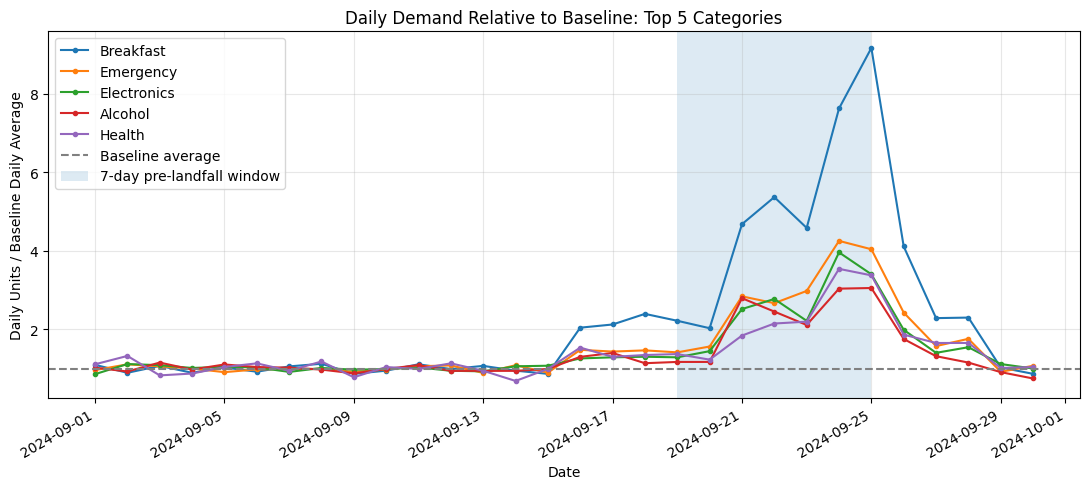

In [9]:
import matplotlib.pyplot as plt

# Select the five categories with the largest percentage increases
top5 = q1_results.dropna(
    subset=["percent_increase"]
).head(5).index

# Index daily sales relative to each category's baseline
indexed_sales = daily_category_sales[top5].div(
    baseline_avg[top5].replace(0, np.nan)
)

fig, ax = plt.subplots(figsize=(11, 5))

for category in top5:
    ax.plot(
        indexed_sales.index,
        indexed_sales[category],
        marker="o",
        markersize=3,
        label=category
    )

# Show baseline and pre-landfall window
ax.axhline(
    1, color="gray", linestyle="--",
    label="Baseline average"
)

ax.axvspan(
    pd.Timestamp(surge_start),
    pd.Timestamp(surge_end),
    alpha=0.15,
    label="7-day pre-landfall window"
)

ax.set_title(
    "Daily Demand Relative to Baseline: Top 5 Categories"
)
ax.set_xlabel("Date")
ax.set_ylabel("Daily Units / Baseline Daily Average")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


### Q1 — Demand Surge Findings
We compared average daily unit sales across 10 product categories during the baseline period (September 1–14, 2024) and seven days before landfall (September 19–25, 2024). We used daily averages because the two periods had different lengths.

The largest increases were in Breakfast (409.76%), Emergency (182.25%), Electronics (151.48%), Alcohol (125.52%), and Health (124.28%). Breakfast had the largest percentage increase, from 73.93 to 376.86 units per day. Emergency products had the largest absolute increase in the top five, from 356.57 to 1,006.43 units per day.

The visualization shows that demand generally increased as landfall approached, particularly between September 21 and September 25. Breakfast sales rose the most, reaching about nine times their usual daily level on September 25. Other categories are more likely to represent moderate increases, generally peaking around three to five times their baseline levels.

These findings suggest that Walmart should prioritize additional inventory for breakfast and emergency products before hurricanes. Breakfast sales grew the most in percentage terms, and Emergency products sold more units. Walmart should plan to stock more of both before a storm.

Our analysis excluded transactions with missing timestamps and negative quantities. Therefore, results could only reflect recorded positive sales and may not capture returns or transactions without valid dates. Sales rose before the hurricane, but we can’t tell from these data whether the storm caused the increase.

## Q2 — SKU Consolidation

In [10]:
# Group equivalent SKUs across the full product catalog
sku_groups = {
    "Pop-Tarts Strawberry": [
        "PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"
    ],
    "Bottled Water": [
        "WTR-24", "WATER24PK", "WTR_24PK"
    ],
    "AA Batteries": [
        "BATT-100", "BAT-AA4", "BATT_AA_4PK"
    ],
    "LED Flashlight": [
        "FLASH-01", "LED-FLASH"
    ],
    "Light Beer": [
        "BEER-24", "LTBEER24"
    ],
    "Monopoly Board Game": [
        "BG-MONO", "MONOPOLY-01", "GAME-MONO"
    ],
    "Playing Cards": [
        "CARDS-01", "PLAYCARD-STD"
    ],
    "Streaming Device": [
        "STREAM-01", "ROKU-STD"
    ],
    "Canned Soup": [
        "SOUP-CAN", "CNSOUP-01"
    ],
    "White Bread": [
        "BREAD-WH", "WHITEBREAD"
    ],
    "Peanut Butter": [
        "PB-16", "PNUTBTR-16"
    ],
    "Emergency Candles": [
        "CNDL-EM", "CANDLE-EMRG"
    ],
    "First-Aid Kit": [
        "FAID-01", "FIRSTAID-KIT"
    ],
    "Portable Charger": [
        "CHRG-PORT", "PORTCHARGER"
    ],
    "Chips Variety Pack": [
        "CHIPS-VP", "CHIPVARIETY"
    ],
    "Paper Towels": [
        "PTOWEL-6", "PAPERTOWEL6"
    ],
    "Toilet Paper": [
        "TP-12", "TOILETPAPER12"
    ],
    "Baby Diapers": [
        "DIAP-S3", "DIAPERS-3"
    ],
    "Baby Formula": [
        "BFORM-01", "BABYFORMULA"
    ],
    "Heavy Duty Tarp": [
        "TARP-HD", "HDTARP-01"
    ]
}

# Create SKU-to-product mapping
full_sku_map = {
    sku: product
    for product, skus in sku_groups.items()
    for sku in skus
}

# Check coverage of the original product catalog
catalog_skus = set(products["sku"].astype(str).str.strip().str.upper())
mapped_skus = set(full_sku_map)

assert catalog_skus == mapped_skus, "Some catalog SKUs are not mapped!"

# Apply the mapping to cleaned transactions
cleaned_sales["canonical_product"] = (
    cleaned_sales["sku"].astype("string").str.strip().str.upper()
    .map(full_sku_map)
)

assert cleaned_sales["canonical_product"].notna().all()

# Check that consolidation does not change total quantity
before_total = cleaned_sales["quantity"].sum()
after_total = cleaned_sales.groupby(
    "canonical_product"
)["quantity"].sum().sum()

assert before_total == after_total

print("Original SKUs:", len(catalog_skus))
print("Canonical product groups:", len(sku_groups))
print("Unmapped SKUs:", len(catalog_skus - mapped_skus))
print("Total quantity preserved:", before_total == after_total)


Original SKUs: 45
Canonical product groups: 20
Unmapped SKUs: 0
Total quantity preserved: True


In [11]:
# Create an auditable mapping table with package sizes
sku_mapping_table = products[
    ["sku", "product_name", "package_size"]
].copy()

sku_mapping_table["canonical_product"] = (
    sku_mapping_table["sku"].astype(str).str.strip().str.upper()
    .map(full_sku_map)
)

sku_mapping_table = sku_mapping_table.sort_values(
    ["canonical_product", "sku"]
)

display(sku_mapping_table)

# Identify groups with inconsistent package descriptions
package_check = (
    sku_mapping_table.groupby("canonical_product")["package_size"]
    .nunique(dropna=False)
)

print("Product groups with multiple package-size labels:")
display(package_check[package_check > 1])


,sku,product_name,package_size,canonical_product
8,BAT-AA4,AA Batteries 4-Pack,4pk,AA Batteries
7,BATT-100,BATTERIES AA 4PK,6 pack,AA Batteries
9,BATT_AA_4PK,AA Batteries 4-Pack,24 pack,AA Batteries
39,DIAP-S3,Baby Diapers - Size 3,single,Baby Diapers
40,DIAPERS-3,DIAPERS SZ 3,6 pack,Baby Diapers
42,BABYFORMULA,Baby Formula,6 pack,Baby Formula
41,BFORM-01,Infant Formula,4-pack,Baby Formula
5,WATER24PK,Bottled Water 24-Pack,24 pack,Bottled Water
4,WTR-24,BOTTLED WATER 24PK,1 pack,Bottled Water
6,WTR_24PK,Water - 24 Pack,1 pack,Bottled Water


Product groups with multiple package-size labels:


,package_size
canonical_product,
AA Batteries,3
Baby Diapers,2
Baby Formula,2
Bottled Water,2
Chips Variety Pack,2
Emergency Candles,2
Heavy Duty Tarp,2
LED Flashlight,2
Monopoly Board Game,2


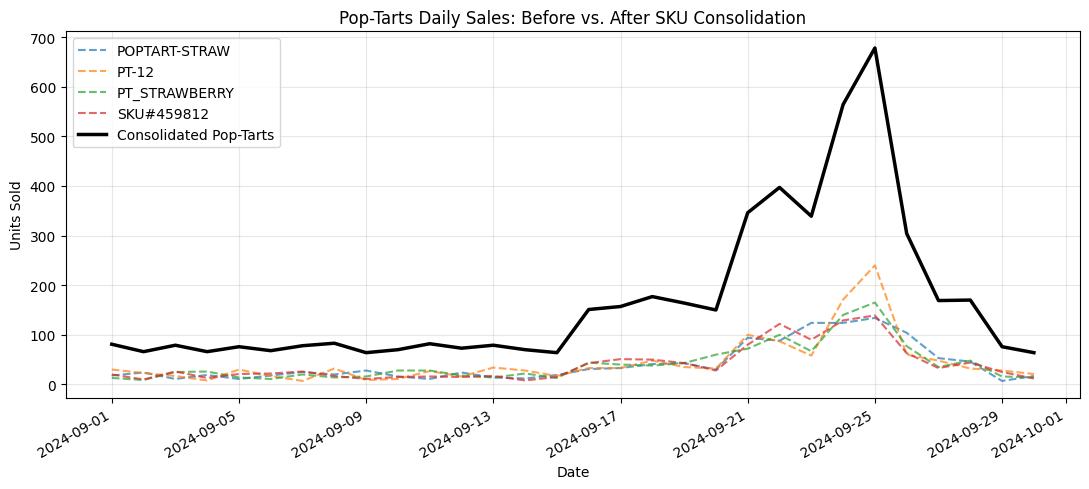

Total recorded units: 5005
Daily totals preserved: True
Average daily consolidated sales: 166.83


In [12]:
# Select Pop-Tarts transactions with valid dates
poptarts = cleaned_sales[
    cleaned_sales["canonical_product"] == "Pop-Tarts Strawberry"
].dropna(subset=["timestamp", "quantity"]).copy()

# Use nonnegative recorded sales for demand analysis
poptarts = poptarts[poptarts["quantity"] >= 0]
poptarts["date"] = poptarts["timestamp"].dt.normalize()

# Daily sales before consolidation (separate SKUs)
before = poptarts.pivot_table(
    index="date",
    columns="sku",
    values="quantity",
    aggfunc="sum",
    fill_value=0
)

# Daily sales after consolidation
after = before.sum(axis=1)

# Visualize fragmented vs. consolidated sales
fig, ax = plt.subplots(figsize=(11, 5))

for sku in before.columns:
    ax.plot(
        before.index,
        before[sku],
        linestyle="--",
        alpha=0.7,
        label=sku
    )

ax.plot(
    after.index,
    after,
    linewidth=2.5,
    color="black",
    label="Consolidated Pop-Tarts"
)

ax.set_title("Pop-Tarts Daily Sales: Before vs. After SKU Consolidation")
ax.set_xlabel("Date")
ax.set_ylabel("Units Sold")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Verify totals
print("Total recorded units:", after.sum())
print("Daily totals preserved:", (before.sum(axis=1) == after).all())
print("Average daily consolidated sales:", round(after.mean(), 2))


### Q2 — SKU Consolidation Findings

We examined all 45 SKUs in the product catalog and consolidated them into 20 canonical product groups, with no unmapped SKUs. We also verified that the total recorded quantity remained unchanged after consolidation.

For strawberry Pop-Tarts, we combined four SKU variants into a single product group. The combined daily sales averaged 166.83 recorded units, with 5005 units sold during the observed period. The visualization shows that individual SKU-level sales substantially underestimated total product-family demand, especially during the pre-hurricane surge. Sales reached the peak around September 25, when combined daily volume was considerably higher than any individual SKU.

We also identified inconsistencies in package-size labels across 16 product groups. For example, Pop-Tarts appeared as "4-pack," "4pk," "4 pack," and "6 pack." We treated equivalent labels as the same packaging format but retained differences in actual pack sizes. Since the package-size metadata may be inconsistent, we did not convert recorded quantities into individual pastry units.

These findings demonstrate why combining SKU is important for Walmart's inventory planning. Without combination, demand may appear fragmented across product identifiers, finally leads to understocking. However, Walmart should validate the pack size of each SKU before restocking. SKUs in the same product family can contain different sizes or quantities of items each package.



## Q3 — Weather Correlation


In [13]:
# Update the existing weather API to include barometric pressure
weather_url = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": 28.5383,
    "longitude": -81.3792,
    "start_date": "2024-09-01",
    "end_date": "2024-09-30",
    "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max,pressure_msl_mean",
    "timezone": "America/New_York"
}

# Request weather data with retries
for attempt in range(3):
    try:
        response = requests.get(weather_url, params=weather_params, timeout=30)
        response.raise_for_status()
        weather_data = response.json()
        break
    except requests.exceptions.RequestException:
        if attempt == 2:
            raise
        time.sleep(2 ** attempt)

weather_df = pd.DataFrame(weather_data["daily"])
weather_df = weather_df.rename(columns={"time": "date"})
weather_df["date"] = pd.to_datetime(weather_df["date"])
weather_df["store_id"] = "FL-239"
weather_df["source"] = "Open-Meteo Historical Weather API"

print("Weather records:", len(weather_df))
print("API source:", response.url)
display(weather_df.head())

assert "pressure_msl_mean" in weather_df.columns

Weather records: 30
API source: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max%2Cpressure_msl_mean&timezone=America%2FNew_York


,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,pressure_msl_mean,store_id,source
0,2024-09-01,25.8,6.4,18.7,1014.1,FL-239,Open-Meteo Historical Weather API
1,2024-09-02,25.9,22.0,12.7,1014.1,FL-239,Open-Meteo Historical Weather API
2,2024-09-03,26.1,32.7,20.6,1015.7,FL-239,Open-Meteo Historical Weather API
3,2024-09-04,26.2,21.2,12.6,1017.7,FL-239,Open-Meteo Historical Weather API
4,2024-09-05,25.8,20.8,15.2,1017.2,FL-239,Open-Meteo Historical Weather API


Categories analyzed: 10
Days analyzed: 30


,wind_speed_10m_max,precipitation_sum,pressure_msl_mean
Alcohol,0.410,-0.064,-0.341
Baby,-0.124,-0.260,0.137
Breakfast,0.457,-0.232,-0.387
Electronics,0.249,-0.167,-0.170
Emergency,0.506,-0.242,-0.375
Entertainment,0.414,-0.177,-0.200
Grocery,0.160,-0.305,-0.002
Health,0.365,-0.207,-0.295
Household,0.372,-0.200,-0.244
Snacks,0.074,0.056,0.005


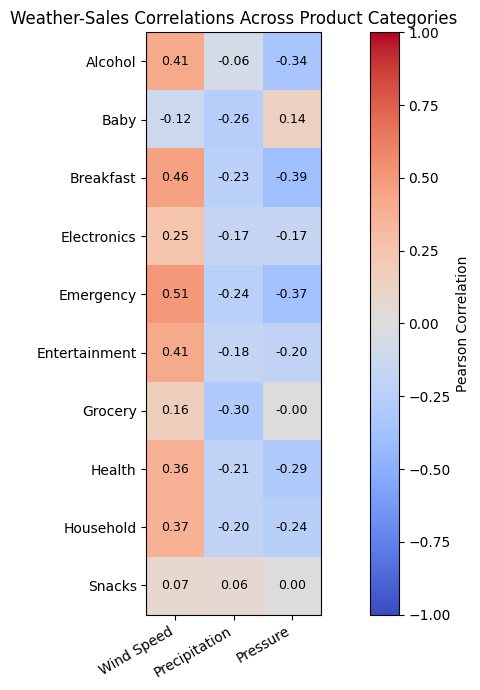

In [14]:
# Use Q1's cleaned and standardized categories for Orlando
q3_sales = q1_sales[q1_sales["store_id"] == "FL-239"].copy()

# Aggregate daily sales by category
q3_daily = (
    q3_sales.groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

# Include all dates in the weather dataset
q3_daily = q3_daily.reindex(
    weather_df["date"], fill_value=0
)
q3_daily.index.name = "date"

# Join daily category sales with weather by local date
q3_joined = q3_daily.join(
    weather_df.set_index("date")[
        ["wind_speed_10m_max", "precipitation_sum", "pressure_msl_mean"]
    ],
    how="inner",
    validate="one_to_one"
)

weather_vars = [
    "wind_speed_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

categories = list(q3_daily.columns)

assert len(q3_joined) == len(q3_daily)
assert q3_joined[weather_vars].notna().all().all()

# Pearson correlation for each category and weather indicator
correlation_table = pd.DataFrame(
    {
        var: {
            category: q3_joined[category].corr(q3_joined[var])
            for category in categories
        }
        for var in weather_vars
    }
)

print("Categories analyzed:", len(categories))
print("Days analyzed:", len(q3_joined))
display(correlation_table.round(3))

# Visualization: correlation heatmap
fig, ax = plt.subplots(figsize=(10, 7))
values = correlation_table.values

im = ax.imshow(values, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(weather_vars)))
ax.set_xticklabels(
    ["Wind Speed", "Precipitation", "Pressure"],
    rotation=30,
    ha="right"
)
ax.set_yticks(range(len(categories)))
ax.set_yticklabels(categories)

for i in range(len(categories)):
    for j in range(len(weather_vars)):
        ax.text(j, i, f"{values[i, j]:.2f}",
                ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Pearson Correlation")
ax.set_title("Weather-Sales Correlations Across Product Categories")
plt.tight_layout()
plt.show()


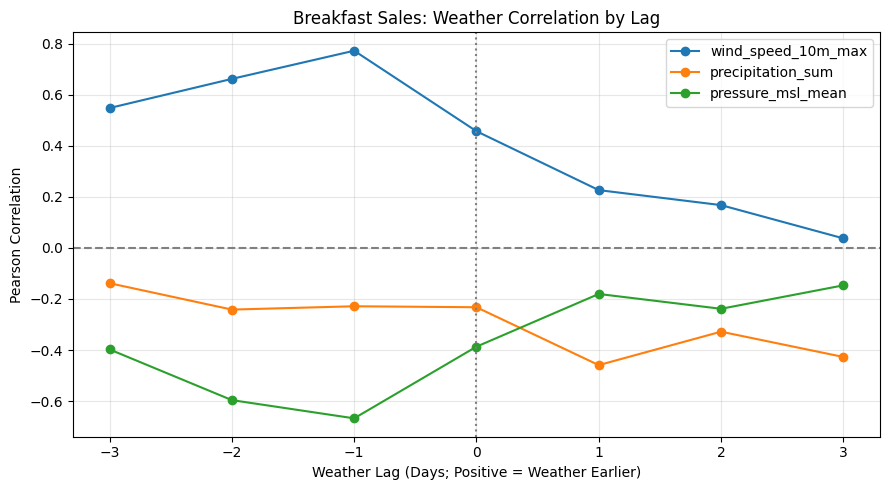

wind_speed_10m_max: strongest correlation = 0.772, lag = -1 days
precipitation_sum: strongest correlation = -0.459, lag = 1 days
pressure_msl_mean: strongest correlation = -0.667, lag = -1 days


In [15]:
# Test lag relationships for Breakfast sales
target_category = "Breakfast"
lags = range(-3, 4)

lag_results = []

for var in weather_vars:
    for lag in lags:
        # Positive lag: weather occurs before sales
        # Negative lag: sales occur before weather
        shifted_weather = q3_joined[var].shift(lag)

        valid = pd.DataFrame({
            "sales": q3_joined[target_category],
            "weather": shifted_weather
        }).dropna()

        corr = valid["sales"].corr(valid["weather"])

        lag_results.append({
            "weather_variable": var,
            "lag_days": lag,
            "correlation": corr
        })

lag_df = pd.DataFrame(lag_results)

# Plot correlations at different lags
fig, ax = plt.subplots(figsize=(9, 5))

for var in weather_vars:
    subset = lag_df[lag_df["weather_variable"] == var]
    ax.plot(
        subset["lag_days"],
        subset["correlation"],
        marker="o",
        label=var
    )

ax.axhline(0, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle=":")
ax.set_title("Breakfast Sales: Weather Correlation by Lag")
ax.set_xlabel("Weather Lag (Days; Positive = Weather Earlier)")
ax.set_ylabel("Pearson Correlation")
ax.set_xticks(list(lags))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Report strongest absolute correlation for each weather variable
for var in weather_vars:
    subset = lag_df[lag_df["weather_variable"] == var].dropna()
    strongest = subset.loc[subset["correlation"].abs().idxmax()]

    print(
        f"{var}: strongest correlation = "
        f"{strongest['correlation']:.3f}, "
        f"lag = {int(strongest['lag_days'])} days"
    )

### Q3 — Weather Correlation Findings

We retrieved historical weather data for Orlando, from the Open-Meteo API, including maximum daily wind speed, precipitation, and mean sea-level pressure. We aligned the weather data with September 2024 sales records by local date and calculated Pearson correlations across all 10 standardized product categories over 30 days.

Wind speed showed the strongest positive correlations with Emergency (r = 0.506) and Breakfast (r = 0.457), suggesting that sales in these categories tend to increase on windier days. Mean sea-level pressure was negatively correlated with Breakfast (r = -0.387) and Emergency (r = -0.375), indicating that higher sales tended to coincide with lower pressure. Precipitation showed generally weaker relationships, including Grocery (r = -0.305) and Baby (r = -0.260). The combined Health category had correlations of 0.365 with wind speed, -0.207 with precipitation, and -0.295 with pressure.

We also examined lagged correlations from -3 to +3 days for Breakfast, the category with the largest demand surge in Question 1. The strongest wind-speed correlation was r = 0.772 at a lag of -1 day, meaning Breakfast sales were most strongly associated with wind conditions on the following day. Similarly, pressure had its strongest correlation at a lag of -1 day (r = -0.667). Precipitation showed its strongest correlation at a lag of +1 day (r = -0.459), indicating an association between current sales and precipitation on the previous day.

These findings suggest that purchasing activity may increase before worsening wind conditions, which could help Walmart anticipate demand for essential products. However, correlations do not lead to absolute causatio. The lag patterns may be influenced by shared hurricane-related trends. Since the analysis only use 30 days from one Orlando store, additional weather events and locations will be needed before using these relationships for inventory forecasting.



## Q4 — Store-Level Patterns

In [16]:
# Q4: Compare demand surges across Florida stores

# Use the cleaned, nonnegative sales from Q1
q4_sales = q1_sales.copy()

# Daily total quantity for each store
store_daily = (
    q4_sales.groupby(["store_id", "date"])["quantity"]
    .sum()
    .reset_index()
)

# Use the same comparison periods as Q1
baseline = store_daily[
    store_daily["date"].between(baseline_start, baseline_end)
]

surge = store_daily[
    store_daily["date"].between(surge_start, surge_end)
]

# Calculate average daily units, including zero-sale days
baseline_store = baseline.groupby("store_id")["quantity"].sum() / 14
surge_store = surge.groupby("store_id")["quantity"].sum() / 7

store_results = pd.DataFrame({
    "baseline_daily_avg": baseline_store,
    "surge_daily_avg": surge_store
}).fillna(0)

store_results["percent_increase"] = (
    (store_results["surge_daily_avg"] /
     store_results["baseline_daily_avg"].replace(0, np.nan) - 1)
    * 100
)

# Add store location information
store_info = cleaned_stores.drop_duplicates(
    subset=["store_id"]
)[["store_id", "city", "region", "latitude", "longitude"]]

store_results = (
    store_results.reset_index()
    .merge(store_info, on="store_id", how="left",
           validate="one_to_one")
)

# Identify possible outliers using the IQR rule
q1 = store_results["percent_increase"].quantile(0.25)
q3 = store_results["percent_increase"].quantile(0.75)
iqr = q3 - q1

store_results["outlier"] = (
    (store_results["percent_increase"] < q1 - 1.5 * iqr) |
    (store_results["percent_increase"] > q3 + 1.5 * iqr)
)

store_results = store_results.sort_values(
    "percent_increase", ascending=False
)

print("Stores analyzed:", len(store_results))
print("Potential outliers:", store_results["outlier"].sum())

display(store_results.round(2))


Stores analyzed: 12
Potential outliers: 3


,store_id,baseline_daily_avg,surge_daily_avg,percent_increase,city,region,latitude,longitude,outlier
6,FL-330,86.93,235.43,170.83,Miami,South,25.76,-80.19,True
10,FL-619,86.36,224.14,159.55,Tallahassee,Panhandle,NaN,NaN,True
1,FL-105,91.79,231.71,152.45,Tampa,West,27.95,-82.46,False
7,FL-412,91.14,222.86,144.51,Jacksonville,North,30.33,-81.66,False
5,FL-302,98.00,239.43,144.31,Lakeland,Central,28.04,-81.95,False
11,FL-710,93.29,227.86,144.26,Pensacola,Panhandle,30.42,-87.22,False
4,FL-287,91.00,220.14,141.92,Kissimmee,Central,28.29,-81.41,False
8,FL-445,95.93,232.00,141.85,St. Petersburg,West,27.77,-82.64,False
2,FL-156,95.21,229.14,140.66,Daytona Beach,East,29.21,-81.02,False
0,FL-078,92.07,219.00,137.86,Gainesville,North,29.65,-82.32,False


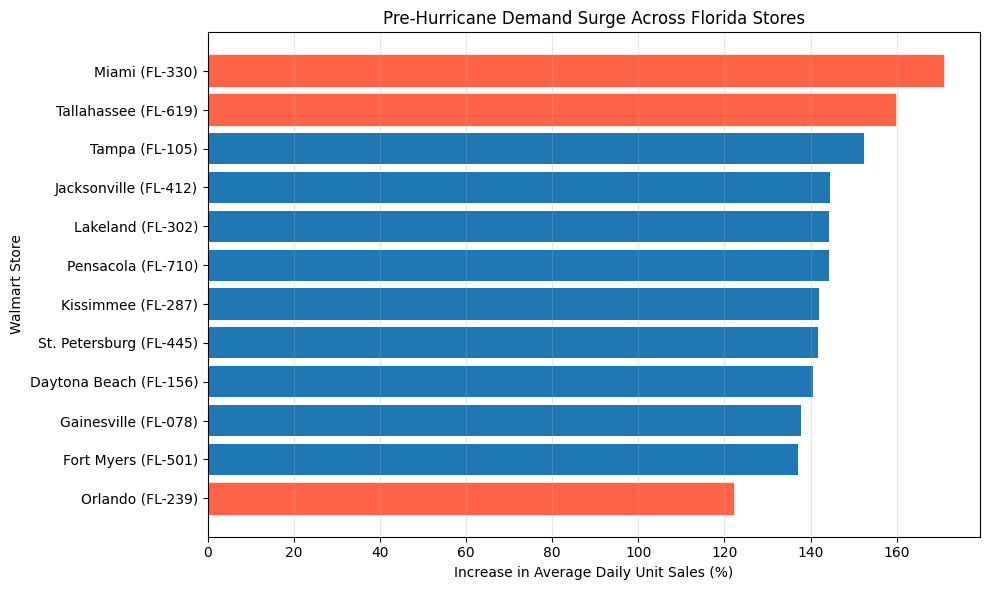

Average store-level surge by region (%):


,percent_increase
region,
South,170.83
Panhandle,159.55
Panhandle,144.26
West,143.76
North,141.19
East,140.66
Central,136.11


First day exceeding 1.5x baseline:


,store_id,city,first_surge_date
6,FL-287,Kissimmee,2024-09-19
1,FL-619,Tallahassee,2024-09-20
0,FL-330,Miami,2024-09-21
2,FL-105,Tampa,2024-09-21
3,FL-412,Jacksonville,2024-09-21
4,FL-302,Lakeland,2024-09-21
5,FL-710,Pensacola,2024-09-21
7,FL-445,St. Petersburg,2024-09-21
8,FL-156,Daytona Beach,2024-09-21
9,FL-078,Gainesville,2024-09-21


In [17]:
# Show store-level surge percentages
plot_data = store_results.sort_values("percent_increase")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data["city"] + " (" + plot_data["store_id"] + ")",
    plot_data["percent_increase"]
)

# Highlight potential outliers
for bar, is_outlier in zip(bars, plot_data["outlier"]):
    if is_outlier:
        bar.set_color("tomato")

ax.set_title("Pre-Hurricane Demand Surge Across Florida Stores")
ax.set_xlabel("Increase in Average Daily Unit Sales (%)")
ax.set_ylabel("Walmart Store")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Compare average surge by region
region_results = (
    store_results.groupby("region")["percent_increase"]
    .mean()
    .sort_values(ascending=False)
)

print("Average store-level surge by region (%):")
display(region_results.round(2))

# Check when each store first exceeded 1.5x its baseline
onset_results = []

for _, row in store_results.iterrows():
    sid = row["store_id"]
    threshold = row["baseline_daily_avg"] * 1.5

    daily = surge[
        (surge["store_id"] == sid) &
        (surge["quantity"] > threshold)
    ].sort_values("date")

    onset_results.append({
        "store_id": sid,
        "city": row["city"],
        "first_surge_date": (
            daily["date"].iloc[0] if not daily.empty else pd.NaT
        )
    })

onset_df = pd.DataFrame(onset_results)

print("First day exceeding 1.5x baseline:")
display(onset_df.sort_values("first_surge_date"))


In [18]:
# Standardize region labels before comparison
store_results["region"] = (
    store_results["region"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Recalculate average surge by region
region_results = (
    store_results.groupby("region")["percent_increase"]
    .mean()
    .sort_values(ascending=False)
)

print("Corrected regional averages:")
display(region_results.round(2))

# Check store coverage
print("Unique stores in original store data:",
      stores["store_id"].nunique())
print("Unique stores in cleaned transactions:",
      cleaned_sales["store_id"].nunique())
print("Stores analyzed:", store_results["store_id"].nunique())

# Check missing geographic coordinates
print("Stores missing coordinates:",
      store_results[["latitude", "longitude"]].isna().any(axis=1).sum())

Corrected regional averages:


,percent_increase
region,
South,170.83
Panhandle,151.91
West,143.76
North,141.19
East,140.66
Central,136.11


Unique stores in original store data: 14
Unique stores in cleaned transactions: 12
Stores analyzed: 12
Stores missing coordinates: 1


In [19]:
# Match store coordinates with the date each store first crossed the threshold.
path_stores = store_results.dropna(subset=["latitude", "longitude"]).merge(
    onset_df[["store_id", "first_surge_date"]],
    on="store_id",
    validate="one_to_one"
)

# Source: NHC Hurricane Helene Forecast Advisory 10
# Issued September 25, 2024, at 2100 UTC
# https://www.nhc.noaa.gov/archive/2024/al09/al092024.fstadv.010.shtml
# Distances are approximated to the forecast centerline,
# not the actual observed storm path.
scale = np.array([111.2, 111.2 * np.cos(np.deg2rad(28))])

track = np.array([
    (24.1, -86.2),
    (27.4, -85.2),
    (32.1, -84.6)
]) * scale
locations = path_stores[["latitude", "longitude"]].to_numpy(dtype=float) * scale

# Find each store's shortest distance to the forecast centerline.
distances = []
for start, end in zip(track[:-1], track[1:]):
    segment = end - start
    fraction = np.clip((locations - start) @ segment / (segment @ segment), 0, 1)
    closest = start + fraction[:, None] * segment
    distances.append(np.linalg.norm(locations - closest, axis=1))

path_stores["distance_km"] = np.min(distances, axis=0)
path_stores = path_stores.sort_values("distance_km").reset_index(drop=True)

# Compare the five nearest stores with the six remaining stores.
path_stores["distance_group"] = np.where(
    path_stores.index < len(path_stores) // 2, "Nearer", "Farther"
)

path_summary = path_stores.groupby("distance_group").agg(
    stores=("store_id", "size"),
    median_increase_pct=("percent_increase", "median"),
    median_surge_date=("first_surge_date", "median")
)

display(path_summary.reindex(["Nearer", "Farther"]).round(2))

,stores,median_increase_pct,median_surge_date
distance_group,,,
Nearer,5,144.26,2024-09-21
Farther,6,141.29,2024-09-21


### Q4 — Store-Level Geographic Patterns Findings

We compared average daily unit sales across 12 Florida Walmart stores during the baseline period (September 1–14, 2024) and the seven-day pre-landfall period (September 19–25, 2024). All 12 stores experienced increased demand, but the magnitude and timing of these increases varied across locations.

Miami (FL-330) experienced the largest percentage increase at 170.83%, followed by Tallahassee (FL-619) at 159.55% and Tampa (FL-105) at 152.45%. Orlando (FL-239) had the smallest increase at 122.10%. These differences demonstrate that demand did not rise uniformly across Walmart locations.

For each store, we found the first day when sales were more than 50% above its baseline daily average. Kissimmee (FL-287) reached this threshold first on September 19, followed by Tallahassee on September 20. The remaining ten stores reached the threshold on September 21. Using the IQR method, we identified three potential outliers: Miami and Tallahassee with unusually high percentage increases, and Orlando with a relatively low increase.

These findings suggest that Walmart should adjust inventory allocation based on store-level demand rather than applying the same strategy to every location. Stores with larger sales increases may need to carry more inventory, while stores where demand rose earlier may benefit from earlier replenishment.

We estimated each store’s shortest distance to Helene’s forecast centerline using NHC Advisory 10, issued on September 25. The five nearer stores had a median increase in daily sales of 144.26%, compared with 141.29% for the six further stores. Both groups had a median surge onset of September 21. The nearer stores had a slightly larger median increase of 2.97 percentage points, and the groups reached the surge threshold on the same median date. Tallahassee remained in the store-level sales and outlier analysis, and its missing coordinates excluded it from the distance comparison. Sales began rising before the advisory was issued, so we used the forecast path as a geographic reference when comparing sales across stores.

## Q5 — Board Games

In [20]:
# Q5: Investigate board game demand using SQLite
conn = sqlite3.connect(data_dir / "inventory_and_sales.db")

# Query the daily sales summary from SQLite
sql_sales = pd.read_sql_query("""
    SELECT date, store_id, category, total_units
    FROM daily_sales_summary
    WHERE category = 'Entertainment'
""", conn)

# Query inventory for Monopoly board game SKUs
board_skus = ["BG-MONO", "MONOPOLY-01", "GAME-MONO"]

sql_inventory = pd.read_sql_query("""
    SELECT date, store_id, sku,
           units_on_hand, units_on_order, reorder_point
    FROM inventory_levels
    WHERE sku IN ('BG-MONO', 'MONOPOLY-01', 'GAME-MONO')
""", conn)

conn.close()

# Normalize mixed date formats
sql_sales["date"] = pd.to_datetime(
    sql_sales["date"], format="mixed", errors="coerce"
)

sql_inventory["date"] = pd.to_datetime(
    sql_inventory["date"], format="mixed", errors="coerce"
)

# Compare average daily inventory levels across periods
inventory_summary = []

for period, start, end in [
    ("Baseline", "2024-09-01", "2024-09-14"),
    ("Pre-landfall", "2024-09-19", "2024-09-25")
]:
    subset = sql_inventory[
        sql_inventory["date"].between(start, end)
    ]

    inventory_summary.append({
        "period": period,
        "inventory_records": len(subset),
        "avg_units_on_hand": subset["units_on_hand"].mean(),
        "pct_at_or_below_reorder": (
            subset["units_on_hand"] <= subset["reorder_point"]
        ).mean() * 100
    })

inventory_results = pd.DataFrame(inventory_summary)

print("SQLite Entertainment records:", len(sql_sales))
print("SQLite Board Game inventory records:", len(sql_inventory))
display(inventory_results.round(2))


SQLite Entertainment records: 360
SQLite Board Game inventory records: 277


,period,inventory_records,avg_units_on_hand,pct_at_or_below_reorder
0,Baseline,130,79.10,16.15
1,Pre-landfall,65,67.45,38.46


In [21]:

# Compare actual board games, playing cards, and Entertainment

q5_sales = cleaned_sales.dropna(
    subset=["timestamp", "quantity", "sku"]
).copy()

q5_sales = q5_sales[q5_sales["quantity"] >= 0]
q5_sales["date"] = q5_sales["timestamp"].dt.normalize()
q5_sales["sku"] = q5_sales["sku"].astype("string").str.strip().str.upper()

cards_skus = ["CARDS-01", "PLAYCARD-STD"]

# Identify product groups using the catalog mapping
q5_sales["product_group"] = np.select(
    [
        q5_sales["sku"].isin(board_skus),
        q5_sales["sku"].isin(cards_skus)
    ],
    ["Board Games", "Playing Cards"],
    default="Other"
)

# Calculate daily averages using all days in each period
def compare_periods(df, value_col):
    baseline = df[
        df["date"].between("2024-09-01", "2024-09-14")
    ][value_col].sum() / 14

    surge = df[
        df["date"].between("2024-09-19", "2024-09-25")
    ][value_col].sum() / 7

    return {
        "baseline_daily_avg": baseline,
        "surge_daily_avg": surge,
        "percent_increase": (
            (surge / baseline - 1) * 100
            if baseline > 0 else np.nan
        )
    }

results = {}

results["Board Games (CSV)"] = compare_periods(
    q5_sales[q5_sales["product_group"] == "Board Games"],
    "quantity"
)

results["Playing Cards (CSV)"] = compare_periods(
    q5_sales[q5_sales["product_group"] == "Playing Cards"],
    "quantity"
)

results["Entertainment (CSV)"] = compare_periods(
    q5_sales[
        q5_sales["product_group"].isin(["Board Games", "Playing Cards"])
    ],
    "quantity"
)

results["Entertainment (SQLite)"] = compare_periods(
    sql_sales, "total_units"
)

q5_comparison = pd.DataFrame.from_dict(
    results, orient="index"
)

display(q5_comparison.round(2))


,baseline_daily_avg,surge_daily_avg,percent_increase
Board Games (CSV),43.43,111.43,156.58
Playing Cards (CSV),59.21,117.14,97.83
Entertainment (CSV),102.64,228.57,122.69
Entertainment (SQLite),570.54,1394.50,144.42


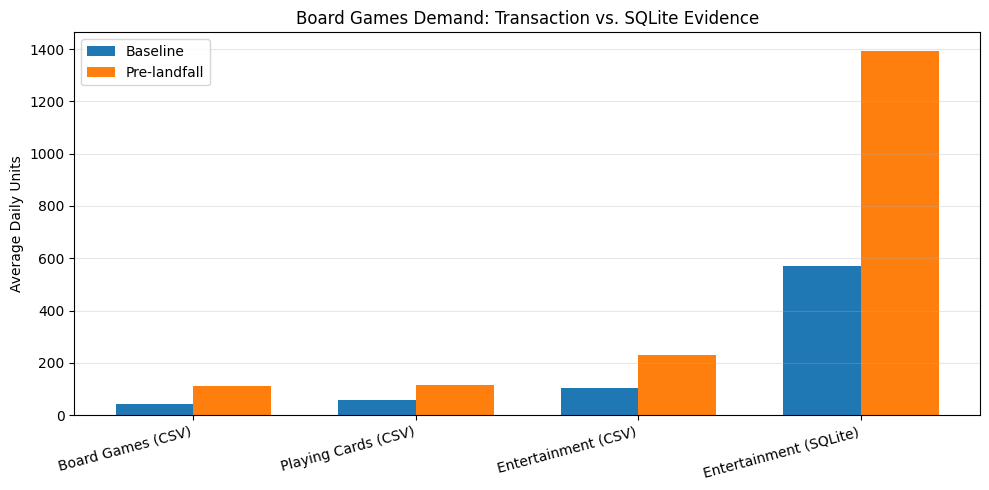

Reported case increase: +250%
Calculated Board Games increase: 156.58 %


In [22]:
# Compare baseline and pre-landfall daily sales
plot_data = q5_comparison.loc[
    ["Board Games (CSV)",
     "Playing Cards (CSV)",
     "Entertainment (CSV)",
     "Entertainment (SQLite)"]]

x = np.arange(len(plot_data))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    plot_data["baseline_daily_avg"],
    width,
    label="Baseline")

ax.bar(
    x + width / 2,
    plot_data["surge_daily_avg"],
    width,
    label="Pre-landfall")

ax.set_xticks(x)
ax.set_xticklabels(plot_data.index, rotation=15, ha="right")
ax.set_ylabel("Average Daily Units")
ax.set_title("Board Games Demand: Transaction vs. SQLite Evidence")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Reported case increase: +250%")
print("Calculated Board Games increase:",
      round(q5_comparison.loc[
          "Board Games (CSV)", "percent_increase"
      ], 2), "%")


In [23]:
# Compare Entertainment sales by store and date.
keys = ["store_id", "date"]
csv_daily = (
    q1_sales.loc[q1_sales["category_clean"].eq("Entertainment")]
    .groupby(keys, as_index=False)["quantity"].sum()
    .rename(columns={"quantity": "csv_units"})
)

sql_daily = sql_sales.copy()
sql_daily["store_id"] = normalize_store_id(sql_daily["store_id"])
sql_daily = (
    sql_daily.groupby(keys, as_index=False)["total_units"].sum()
    .rename(columns={"total_units": "sqlite_units"})
)

audit = csv_daily.merge(
    sql_daily, on=keys, how="outer",
    indicator=True, validate="one_to_one"
)

in_baseline = audit["date"].between(baseline_start, baseline_end)
in_surge = audit["date"].between(surge_start, surge_end)
audit["period"] = np.where(in_baseline, "Baseline", "Pre-landfall")
audit = audit.loc[in_baseline | in_surge].copy()

# Count matched and unmatched store-days.
coverage = (
    audit.groupby(["period", "_merge"], observed=False)
    .size().unstack(fill_value=0)
    .rename(columns={
        "both": "Matched",
        "left_only": "CSV only",
        "right_only": "SQLite only"
    })
)
display(coverage[["Matched", "CSV only", "SQLite only"]])


# Measure the difference on matched store-days.
matched = audit.loc[audit["_merge"].eq("both")].copy()
matched["unit_gap"] = matched["sqlite_units"] - matched["csv_units"]
matched["sqlite_higher"] = matched["unit_gap"].gt(0)

display(matched.groupby("period").agg(
    median_unit_gap=("unit_gap", "median"),
    store_days_with_higher_sqlite=("sqlite_higher", "sum")
))

_merge,Matched,CSV only,SQLite only
period,,,
Baseline,168,0,0
Pre-landfall,84,0,0


,median_unit_gap,store_days_with_higher_sqlite
period,,
Baseline,35.0,168
Pre-landfall,80.0,84


### Q5 — Signal vs. Artifact: Board Games Investigation

We investigated whether the reported 250% increase in board game sales reflected genuine demand or a data artifact by comparing cleaned transaction records with the SQLite sales and inventory database. We consolidated related SKUs and compared average daily sales during the baseline period (September 1–14, 2024) and the seven days before landfall (September 19–25, 2024).

The cleaned transaction data showed that Board Games increased from 43.43 to 111.43 recorded units per day, representing a 156.58% increase, rather than the 250% reported in the case. Playing Cards increased by 97.83%, while the combined Entertainment category increased by 122.69%. This suggests that demand for board games genuinely increased, but the originally reported 250% surge is not supported by our cleaned SKU-level analysis.

We matched the SQLite and CSV Entertainment totals by store ID and date. All 168 baseline store-days and 84 pre-landfall store-days matched. SQLite reported higher sales on every matched store-day. The median difference increased from 35 units per store-day during the baseline to 80 before landfall. The gap persisted even after we aligned the stores and dates. Because SQLite reports sales for the entire Entertainment category, its summary cannot verify the reported 250% increase in board game sales. The SKU-level transaction data showed a 156.58% increase.

Average board game inventory decreased from 79.10 to 67.45 units on hand, while the percentage of inventory records at or below the reorder point increased from 16.15% to 38.46%. This is consistent with increasing inventory pressure during the pre-landfall period, although inventory reporting delays or replenishment timing could also contribute to the pattern.

As a result, for the next storm, Walmart should modestly increase board game inventory at stores where recent sales indicate higher demand.

# Business Recommendation

Before the next hurricane, Walmart should prioritize emergency supplies and breakfast products when planning extra inventory for its Florida stores. In the week before Helene made landfall, emergency supplies had the largest increase in daily units sold, while breakfast products had the largest percentage increase. Walmart should use each store’s recent sales to decide when to replenish and how much to send, since stores closer to the forecast path showed similar timing and only slightly larger sales increases. For board games, Walmart should add a small amount of stock at stores where recent sales point to higher demand.


# Reflection

1. Data Quality Impact
One issue we found was that Strawberry Pop-Tarts sales were recorded under four different SKUs. We grouped the four SKUs and verified that the total recorded quantity stayed the same. On September 25, the four SKUs accounted for 678 packages sold, while the highest-selling SKU accounted for 240. Using that SKU alone to estimate demand for the product family would have undercounted sales by 438 packages that day. This could have led us to recommend too little additional stock.

2. ETL Trade-offs
We kept 884 transactions with missing timestamps in the cleaned dataset and excluded them from analyses that required a date. We could have estimated the missing dates, but the available records gave us little basis for assigning them to specific days. If the estimated dates fell disproportionately in the week before landfall, the sales increase could appear larger than it was. Using only transactions with recorded dates gave us a consistent way to assign sales to each period, though the daily totals may understate actual sales.

3. Pipeline Trust
We agree with the Walmart CDO that the pipeline was the biggest source of risk in this project because errors in date alignment could affect the results before we calculated any correlations. The step we were least confident about was joining Orlando sales to weather data by date. All 30 dates matched, and the join preserved the total sales quantity. We treated the sales timestamps as Orlando local time, and the join checks could only verify that the recorded dates matched. If the timezone assumption was incorrect, some transactions near midnight could shift to another day and affect the one-day lag results.

4. Business vs. Data
Recorded board game sales increased by 156.58%, and the share of inventory records at or below the reorder point rose from 16.15% to 38.46%. Together, these results suggest a greater risk of running low before landfall. The SQLite sales summary covers the entire Entertainment category, so it could not verify the reported 250% increase for board games. We recommended a modest increase at stores where recent sales indicate higher demand to reduce the risk of stockouts while limiting excess inventory. With SKU-level sales and inventory data from more storms, we would check whether the same stores are consistently running low before recommending a larger increase.

5. Team Collaboration
We divided the analysis by question and combined our work in one notebook. Jiaxian led the store-level analysis and used the store coordinates to compare the timing and size of sales increases with distance from Helene’s forecast path. Anya led the board game investigation and used SQL to check whether the inventory records and sales summaries supported what we saw in the transaction data. If we had another week, we would agree on the date windows and cleaning rules before splitting up the analysis. That would make it easier to combine our work and give us more time to review each other’s code and verify the results.